# Credit Card Fraud Detection

## Exploratory Data Analysis

This notebook performs an exploratory analysis of a highly imbalanced credit card transaction dataset.

The primary objective is to understand:

- The structure of the dataset
- The distribution of fraudulent and legitimate transactions
- Transaction amount and time characteristics
- Feature distributions
- Relationships between features
- The challenges introduced by severe class imbalance

The findings from this analysis will guide the preprocessing and machine learning stages of the project.

In [40]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Visualization settings
sns.set_theme(style="whitegrid")

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [41]:
FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Figures will be saved to: {FIGURE_DIR.resolve()}")

Figures will be saved to: C:\Users\Bashar\End-to-End Credit Card Fraud Detection Pipeline\reports\figures


In [42]:
DATA_PATH = "../data/creditcard.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Dataset loaded successfully.
Rows: 284,807
Columns: 31


## 1. Dataset Overview

The first step is to examine the structure and basic characteristics of the dataset.

In [43]:
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [44]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0000,-11.8811,10.0718,-9.8348,-2.0667,-5.3645,-2.6068,-4.9182,7.3053,1.9144,4.3562,-1.5931,2.7119,-0.6893,4.6269,-0.9245,1.1076,1.9917,0.5106,-0.6829,1.4758,0.2135,0.1119,1.0145,-0.5093,1.4368,0.2500,0.9437,0.8237,0.7700,0
284803,172787.0000,-0.7328,-0.0551,2.0350,-0.7386,0.8682,1.0584,0.0243,0.2949,0.5848,-0.9759,-0.1502,0.9158,1.2148,-0.6751,1.1649,-0.7118,-0.0257,-1.2212,-1.5456,0.0596,0.2142,0.9244,0.0125,-1.0162,-0.6066,-0.3953,0.0685,-0.0535,24.7900,0
284804,172788.0000,1.9196,-0.3013,-3.2496,-0.5578,2.6305,3.0313,-0.2968,0.7084,0.4325,-0.4848,0.4116,0.0631,-0.1837,-0.5106,1.3293,0.1407,0.3135,0.3957,-0.5773,0.0014,0.2320,0.5782,-0.0375,0.6401,0.2657,-0.0874,0.0045,-0.0266,67.8800,0
284805,172788.0000,-0.2404,0.5305,0.7025,0.6898,-0.3780,0.6237,-0.6862,0.6791,0.3921,-0.3991,-1.9338,-0.9629,-1.0421,0.4496,1.9626,-0.6086,0.5099,1.1140,2.8978,0.1274,0.2652,0.8000,-0.1633,0.1232,-0.5692,0.5467,0.1088,0.1045,10.0000,0
284806,172792.0000,-0.5334,-0.1897,0.7033,-0.5063,-0.0125,-0.6496,1.5770,-0.4147,0.4862,-0.9154,-1.0405,-0.0315,-0.1881,-0.0843,0.0413,-0.3026,-0.6604,0.1674,-0.2561,0.3829,0.2611,0.6431,0.3768,0.0088,-0.4736,-0.8183,-0.0024,0.0136,217.0000,0


In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [46]:
df.columns.tolist()

['Time',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'Amount',
 'Class']

## 2. Data Quality

Before modeling, we need to determine whether the dataset contains missing values or other obvious data-quality problems.

In [47]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

Series([], dtype: int64)

In [48]:
print(f"Total missing values: {df.isnull().sum().sum():,}")

Total missing values: 0


In [49]:
duplicate_count = df.duplicated().sum()

print(f"Duplicate rows: {duplicate_count:,}")

Duplicate rows: 1,081


## 3. Class Distribution

The target variable is `Class`:

- `0` represents a legitimate transaction.
- `1` represents a fraudulent transaction.

Fraud detection is an extremely imbalanced classification problem, so understanding the class distribution is essential before training any model.

In [50]:
class_counts = df["Class"].value_counts().sort_index()

class_counts

Class
0    284315
1       492
Name: count, dtype: int64

In [51]:
class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

class_summary

,Count,Percentage
Class,,
0,284315,99.8273
1,492,0.1727


In [52]:
legitimate_count = (df["Class"] == 0).sum()
fraud_count = (df["Class"] == 1).sum()

imbalance_ratio = legitimate_count / fraud_count

print(f"Legitimate transactions: {legitimate_count:,}")
print(f"Fraudulent transactions: {fraud_count:,}")
print(f"Imbalance ratio: {imbalance_ratio:.1f}:1")

Legitimate transactions: 284,315
Fraudulent transactions: 492
Imbalance ratio: 577.9:1


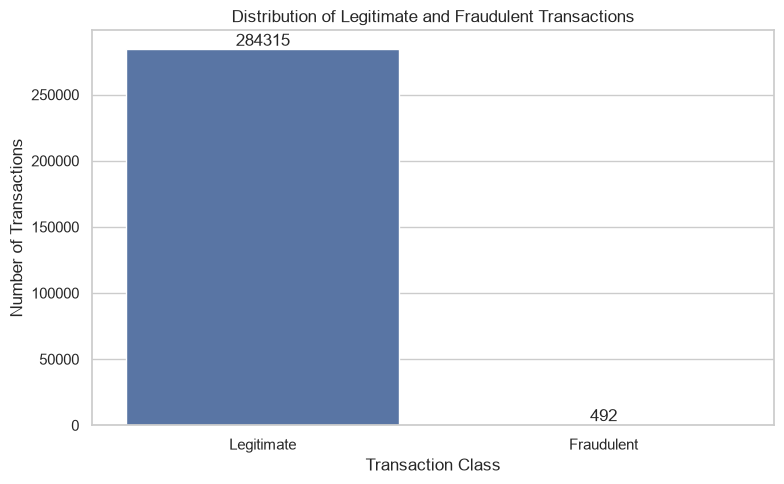

In [53]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Class"
)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])

# Add labels
for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Why Accuracy Alone Is Not Enough

The dataset contains an extreme class imbalance. A classifier that predicts every transaction as legitimate would achieve very high accuracy while detecting no fraudulent transactions.

Therefore, accuracy will not be used as the primary metric for model selection.

Instead, the project will focus on:

- Precision
- Recall
- F1-score
- Precision-Recall AUC
- ROC-AUC
- Confusion Matrix

In particular, Precision-Recall AUC will be important because the positive class is extremely rare.

## 4. Transaction Amount Analysis

Transaction amounts may have substantially different distributions for legitimate and fraudulent transactions. We therefore examine the distribution of transaction amounts before deciding how to preprocess this feature.

In [28]:
df["Amount"].describe()


count   284807.0000
mean        88.3496
std        250.1201
min          0.0000
25%          5.6000
50%         22.0000
75%         77.1650
max      25691.1600
Name: Amount, dtype: float64

In [29]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0000,88.2910,250.1051,0.0000,5.6500,22.0000,77.0500,25691.1600
1,492.0000,122.2113,256.6833,0.0000,1.0000,9.2500,105.8900,2125.8700


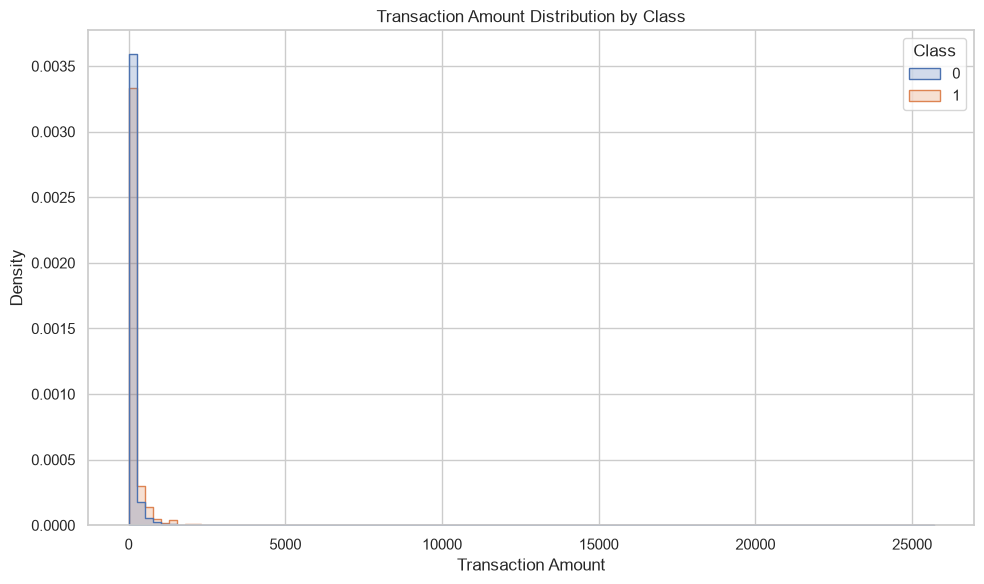

In [30]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=100,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "amount_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

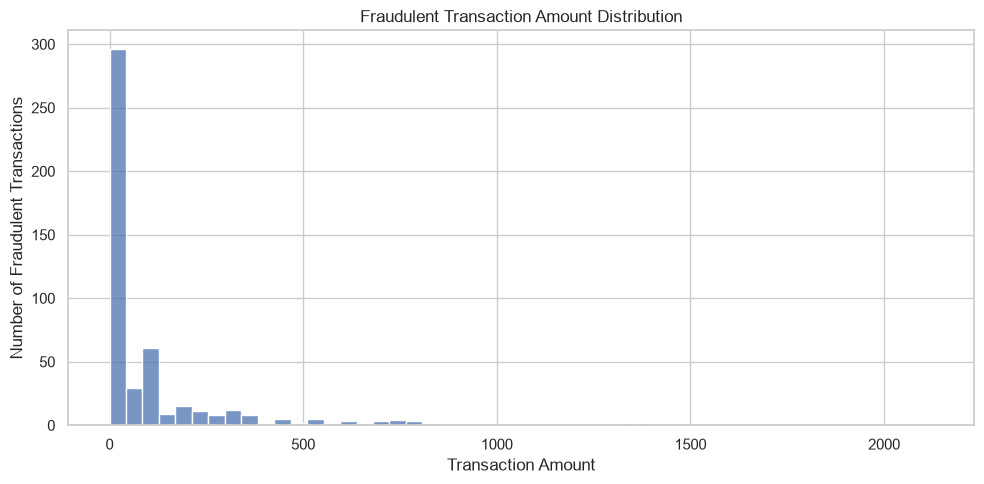

In [31]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df.loc[df["Class"] == 1, "Amount"],
    bins=50
)

plt.title("Fraudulent Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Fraudulent Transactions")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fraud_amount_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Transaction Time Analysis

The `Time` variable represents the elapsed time in seconds from the beginning of the dataset's recording period rather than a conventional calendar timestamp.

For exploratory analysis, we convert this value into an approximate hour-of-day representation to investigate whether transaction activity differs between legitimate and fraudulent transactions.

In [32]:
df["Hour"] = (df["Time"] / 3600) % 24

df.groupby("Class")["Hour"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0000,14.5421,5.8446,0.0000,10.6014,15.0142,19.3328,23.9994
1,492.0000,12.1370,6.7196,0.1128,5.9238,12.0524,17.8037,23.9933


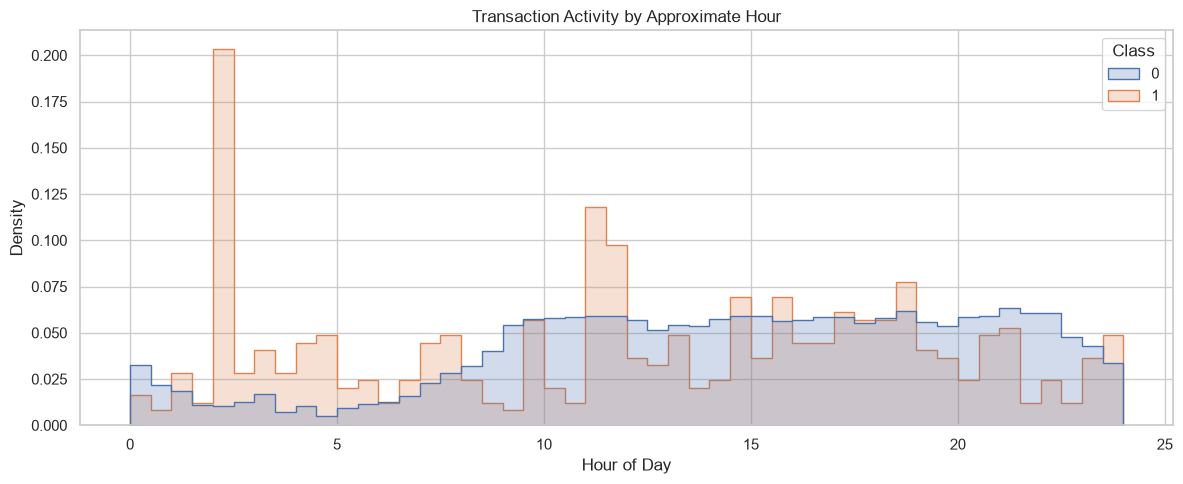

In [33]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Hour",
    hue="Class",
    bins=48,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Activity by Approximate Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Density")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "transaction_time_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Anonymized Feature Analysis

The variables `V1` through `V28` are anonymized numerical features derived from a PCA transformation. Their original real-world meanings are not provided in the dataset, so they will be analyzed statistically rather than assigned assumed interpretations.

In [34]:
feature_columns = [f"V{i}" for i in range(1, 29)]

df[feature_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
V1,284807.0000,0.0000,1.9587,-56.4075,-0.9204,0.0181,1.3156,2.4549
V2,284807.0000,0.0000,1.6513,-72.7157,-0.5985,0.0655,0.8037,22.0577
V3,284807.0000,-0.0000,1.5163,-48.3256,-0.8904,0.1798,1.0272,9.3826
V4,284807.0000,0.0000,1.4159,-5.6832,-0.8486,-0.0198,0.7433,16.8753
V5,284807.0000,0.0000,1.3802,-113.7433,-0.6916,-0.0543,0.6119,34.8017
V6,284807.0000,0.0000,1.3323,-26.1605,-0.7683,-0.2742,0.3986,73.3016
V7,284807.0000,-0.0000,1.2371,-43.5572,-0.5541,0.0401,0.5704,120.5895
V8,284807.0000,0.0000,1.1944,-73.2167,-0.2086,0.0224,0.3273,20.0072
V9,284807.0000,-0.0000,1.0986,-13.4341,-0.6431,-0.0514,0.5971,15.5950
V10,284807.0000,0.0000,1.0888,-24.5883,-0.5354,-0.0929,0.4539,23.7451


In [35]:
feature_means = df.groupby("Class")[feature_columns].mean().T

feature_means.columns = ["Legitimate", "Fraudulent"]

feature_means["Absolute_Mean_Difference"] = (
    feature_means["Fraudulent"] -
    feature_means["Legitimate"]
).abs()

feature_means.sort_values(
    "Absolute_Mean_Difference",
    ascending=False
).head(10)

,Legitimate,Fraudulent,Absolute_Mean_Difference
V3,0.0122,-7.0333,7.0455
V14,0.0121,-6.9717,6.9838
V17,0.0115,-6.6658,6.6774
V12,0.0108,-6.2594,6.2702
V10,0.0098,-5.6769,5.6867
V7,0.0096,-5.5687,5.5784
V1,0.0083,-4.7719,4.7802
V4,-0.0079,4.5420,4.5499
V16,0.0072,-4.1399,4.1471
V11,-0.0066,3.8002,3.8067


## 7. Correlation Analysis

Correlation analysis is used to examine linear relationships among the numerical variables and their relationship with the target variable.

Correlation should not be interpreted as causal evidence or as a substitute for model-based feature importance.

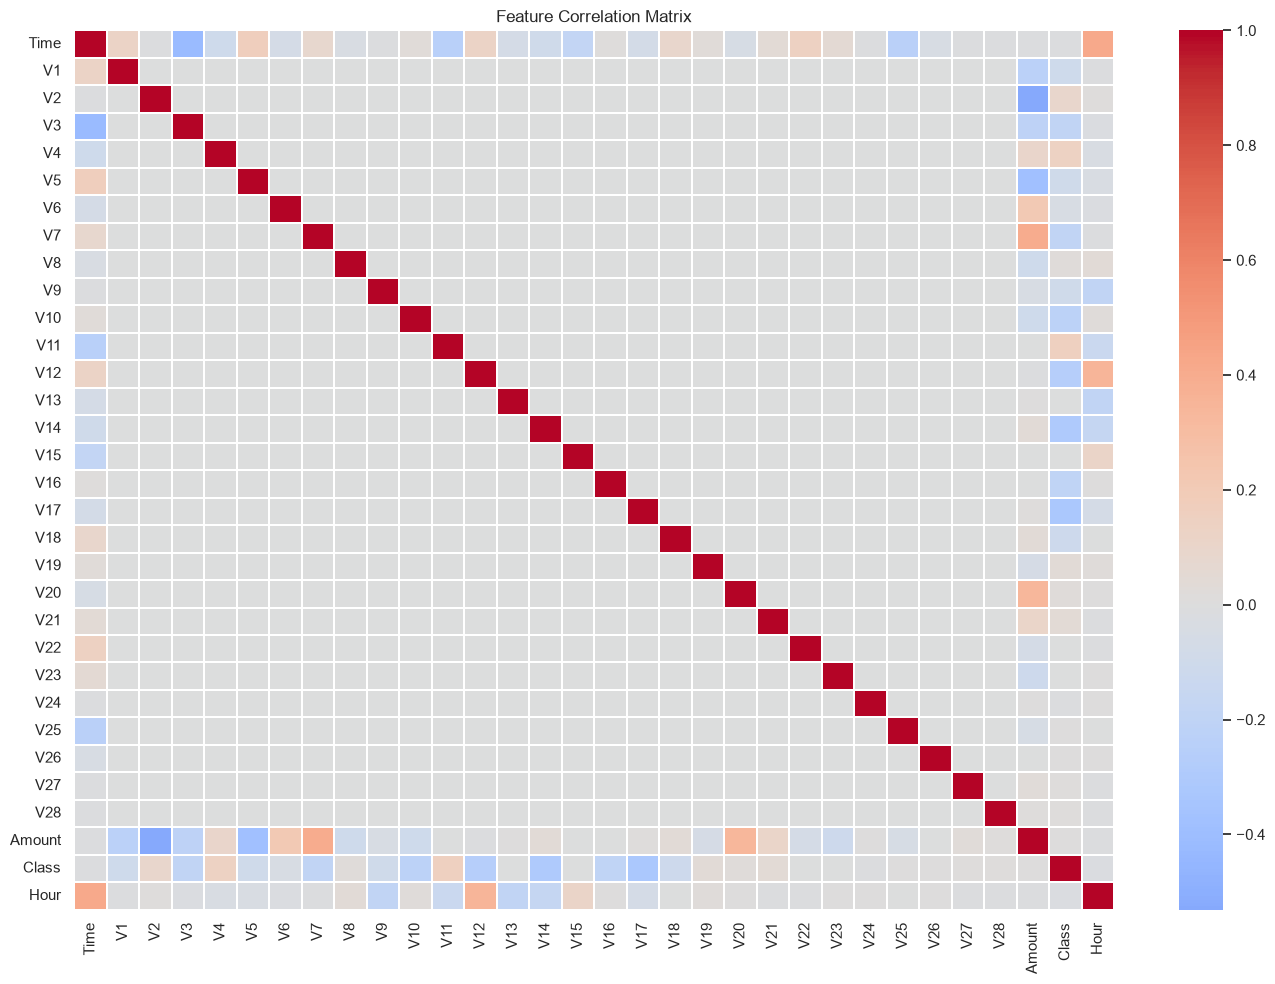

In [36]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [39]:
class_correlations = (
    df.corr(numeric_only=True)["Class"]
    .drop("Class")
    .sort_values()
)

class_correlations

class_correlations.head(10)

class_correlations.tail(10)

Amount   0.0056
V28      0.0095
V27      0.0176
V8       0.0199
V20      0.0201
V19      0.0348
V21      0.0404
V2       0.0913
V4       0.1334
V11      0.1549
Name: Class, dtype: float64

## 8. EDA Conclusions

The exploratory analysis reveals several important characteristics of the dataset:

1. The dataset is highly imbalanced, with fraudulent transactions representing only a very small proportion of all transactions.

2. The extreme class imbalance makes accuracy alone unsuitable as the primary evaluation metric.

3. Transaction amounts have a skewed distribution and should be appropriately considered during preprocessing.

4. The `V1`–`V28` variables are anonymized PCA-derived features, so their real-world meanings cannot be inferred from their names.

5. Several feature distributions and statistical characteristics differ between legitimate and fraudulent transactions, suggesting that the classes contain distinguishable patterns.

6. The `Time` variable can provide temporal information, although its use in the final model should be evaluated carefully.

7. Correlation analysis provides useful exploratory information, but model-based feature importance and explainability methods will be used later to better understand model behavior.

### Next Step

The next stage is to construct a leakage-safe machine learning pipeline, establish baseline models, and investigate different strategies for handling the severe class imbalance.